# Credit Card Customer Segmentation
## 1. Data Preprocessing

**Objective:** Prepare customer spending and payment behaviour data for K-Means clustering through appropriate feature selection, missing-value treatment, transformation and scaling.

The original dataset will remain unchanged throughout preprocessing.

In [8]:
# Import required libraries
import pandas as pd
import numpy as np

from pathlib import Path

# Locate the original dataset
DATA_PATH = Path("../data/raw/CC GENERAL.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH.resolve()}"
    )

# Load the original dataset
df_raw = pd.read_csv(DATA_PATH)

# Create a separate working copy
df_work = df_raw.copy()

# Display dataset information
print("Dataset loaded successfully!")
print("Original dataset shape:", df_raw.shape)
print("Working dataset shape:", df_work.shape)

display(df_work.head())

Dataset loaded successfully!
Original dataset shape: (8950, 18)
Working dataset shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 2. Feature Selection

Exclude the customer identifier and the redundant total purchase amount.

Retain the individual purchase components and other numerical behavioural features for initial clustering.

In [13]:
# Separate customer identifiers
customer_ids = df_work["CUST_ID"].copy()

# Features excluded from clustering
excluded_features = [
    "CUST_ID",
    "PURCHASES"
]

# Select clustering features
feature_cols = [
    col for col in df_work.columns
    if col not in excluded_features
]

X_selected = df_work[feature_cols].copy()

# Display selection results
print("FEATURE SELECTION RESULTS")
print("-" * 40)

print("Original columns:", df_work.shape[1])
print("Excluded features:", excluded_features)
print("Selected features:", len(feature_cols))
print("Selected dataset shape:", X_selected.shape)

print("\nSELECTED FEATURES:")
for feature in feature_cols:
    print("-", feature)

# Validate feature selection
assert "CUST_ID" not in X_selected.columns
assert "PURCHASES" not in X_selected.columns

print("\nFeature selection completed successfully!")


FEATURE SELECTION RESULTS
----------------------------------------
Original columns: 18
Excluded features: ['CUST_ID', 'PURCHASES']
Selected features: 16
Selected dataset shape: (8950, 16)

SELECTED FEATURES:
- BALANCE
- BALANCE_FREQUENCY
- ONEOFF_PURCHASES
- INSTALLMENTS_PURCHASES
- CASH_ADVANCE
- PURCHASES_FREQUENCY
- ONEOFF_PURCHASES_FREQUENCY
- PURCHASES_INSTALLMENTS_FREQUENCY
- CASH_ADVANCE_FREQUENCY
- CASH_ADVANCE_TRX
- PURCHASES_TRX
- CREDIT_LIMIT
- PAYMENTS
- MINIMUM_PAYMENTS
- PRC_FULL_PAYMENT
- TENURE

Feature selection completed successfully!


## 3. Missing Value Treatment

Missing values are handled using median imputation because the affected numerical features exhibit right-skewed distributions.

The original dataset remains unchanged.

In [17]:
from sklearn.impute import SimpleImputer

# Check missing values before imputation
print("Missing values before imputation:")
display(X_selected.isnull().sum()[X_selected.isnull().sum() > 0])

# Apply median imputation
imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_selected),
    columns=X_selected.columns,
    index=X_selected.index
)

# Display imputation values
imputation_values = pd.Series(
    imputer.statistics_,
    index=X_selected.columns,
    name="Imputation Value"
)

print("\nMedian values used for imputation:")
display(imputation_values[X_selected.isnull().any()])

# Validate the result
print("\nMissing values after imputation:",
      X_imputed.isnull().sum().sum())

print("Processed dataset shape:", X_imputed.shape)

assert X_imputed.isnull().sum().sum() == 0

print("\nMissing value treatment completed successfully!")

Missing values before imputation:


CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


Median values used for imputation:


CREDIT_LIMIT        3000.000000
MINIMUM_PAYMENTS     312.343947
Name: Imputation Value, dtype: float64


Missing values after imputation: 0
Processed dataset shape: (8950, 16)

Missing value treatment completed successfully!


## 4. Logarithmic Transformation

Apply the log1p transformation to selected right-skewed monetary and transaction features.

This transformation reduces the influence of extreme values while preserving zero-valued observations.

The imputed dataset will remain unchanged.

In [20]:
# Features selected for logarithmic transformation
log_features = [
    "BALANCE",
    "ONEOFF_PURCHASES",
    "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE",
    "CASH_ADVANCE_TRX",
    "PURCHASES_TRX",
    "CREDIT_LIMIT",
    "PAYMENTS",
    "MINIMUM_PAYMENTS"
]

# Validate selected features
assert all(feature in X_imputed.columns for feature in log_features)

# Ensure log1p can be safely applied
assert (X_imputed[log_features] >= 0).all().all()

# Create an independent transformed dataset
X_transformed = X_imputed.copy()

# Apply log1p transformation
X_transformed[log_features] = np.log1p(
    X_transformed[log_features]
)

# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    "Before Transformation": X_imputed[log_features].skew(),
    "After Transformation": X_transformed[log_features].skew()
})

skewness_comparison["Reduction in Absolute Skewness"] = (
    skewness_comparison["Before Transformation"].abs()
    - skewness_comparison["After Transformation"].abs()
)

print("SKEWNESS COMPARISON")
display(skewness_comparison.round(4))

# Validate transformation
print("\nOriginal dataset shape:", X_imputed.shape)
print("Transformed dataset shape:", X_transformed.shape)
print("Missing values:", X_transformed.isnull().sum().sum())

assert X_transformed.shape == X_imputed.shape
assert np.isfinite(X_transformed.to_numpy()).all()

print("\nLogarithmic transformation completed successfully!")

SKEWNESS COMPARISON


,Before Transformation,After Transformation,Reduction in Absolute Skewness
BALANCE,2.3934,-0.8610,1.5324
ONEOFF_PURCHASES,10.0451,0.1859,9.8592
INSTALLMENTS_PURCHASES,7.2991,-0.0250,7.2741
CASH_ADVANCE,5.1666,0.2626,4.9040
CASH_ADVANCE_TRX,5.7213,0.9401,4.7812
PURCHASES_TRX,4.6307,0.0327,4.5980
CREDIT_LIMIT,1.5226,-0.1014,1.4212
PAYMENTS,5.9076,-1.7783,4.1293
MINIMUM_PAYMENTS,13.8524,0.2697,13.5827



Original dataset shape: (8950, 16)
Transformed dataset shape: (8950, 16)
Missing values: 0

Logarithmic transformation completed successfully!


### 4.1 Before and After Log Transformation

Compare the distributions of selected features before and after log1p transformation to evaluate how effectively skewness has been reduced.

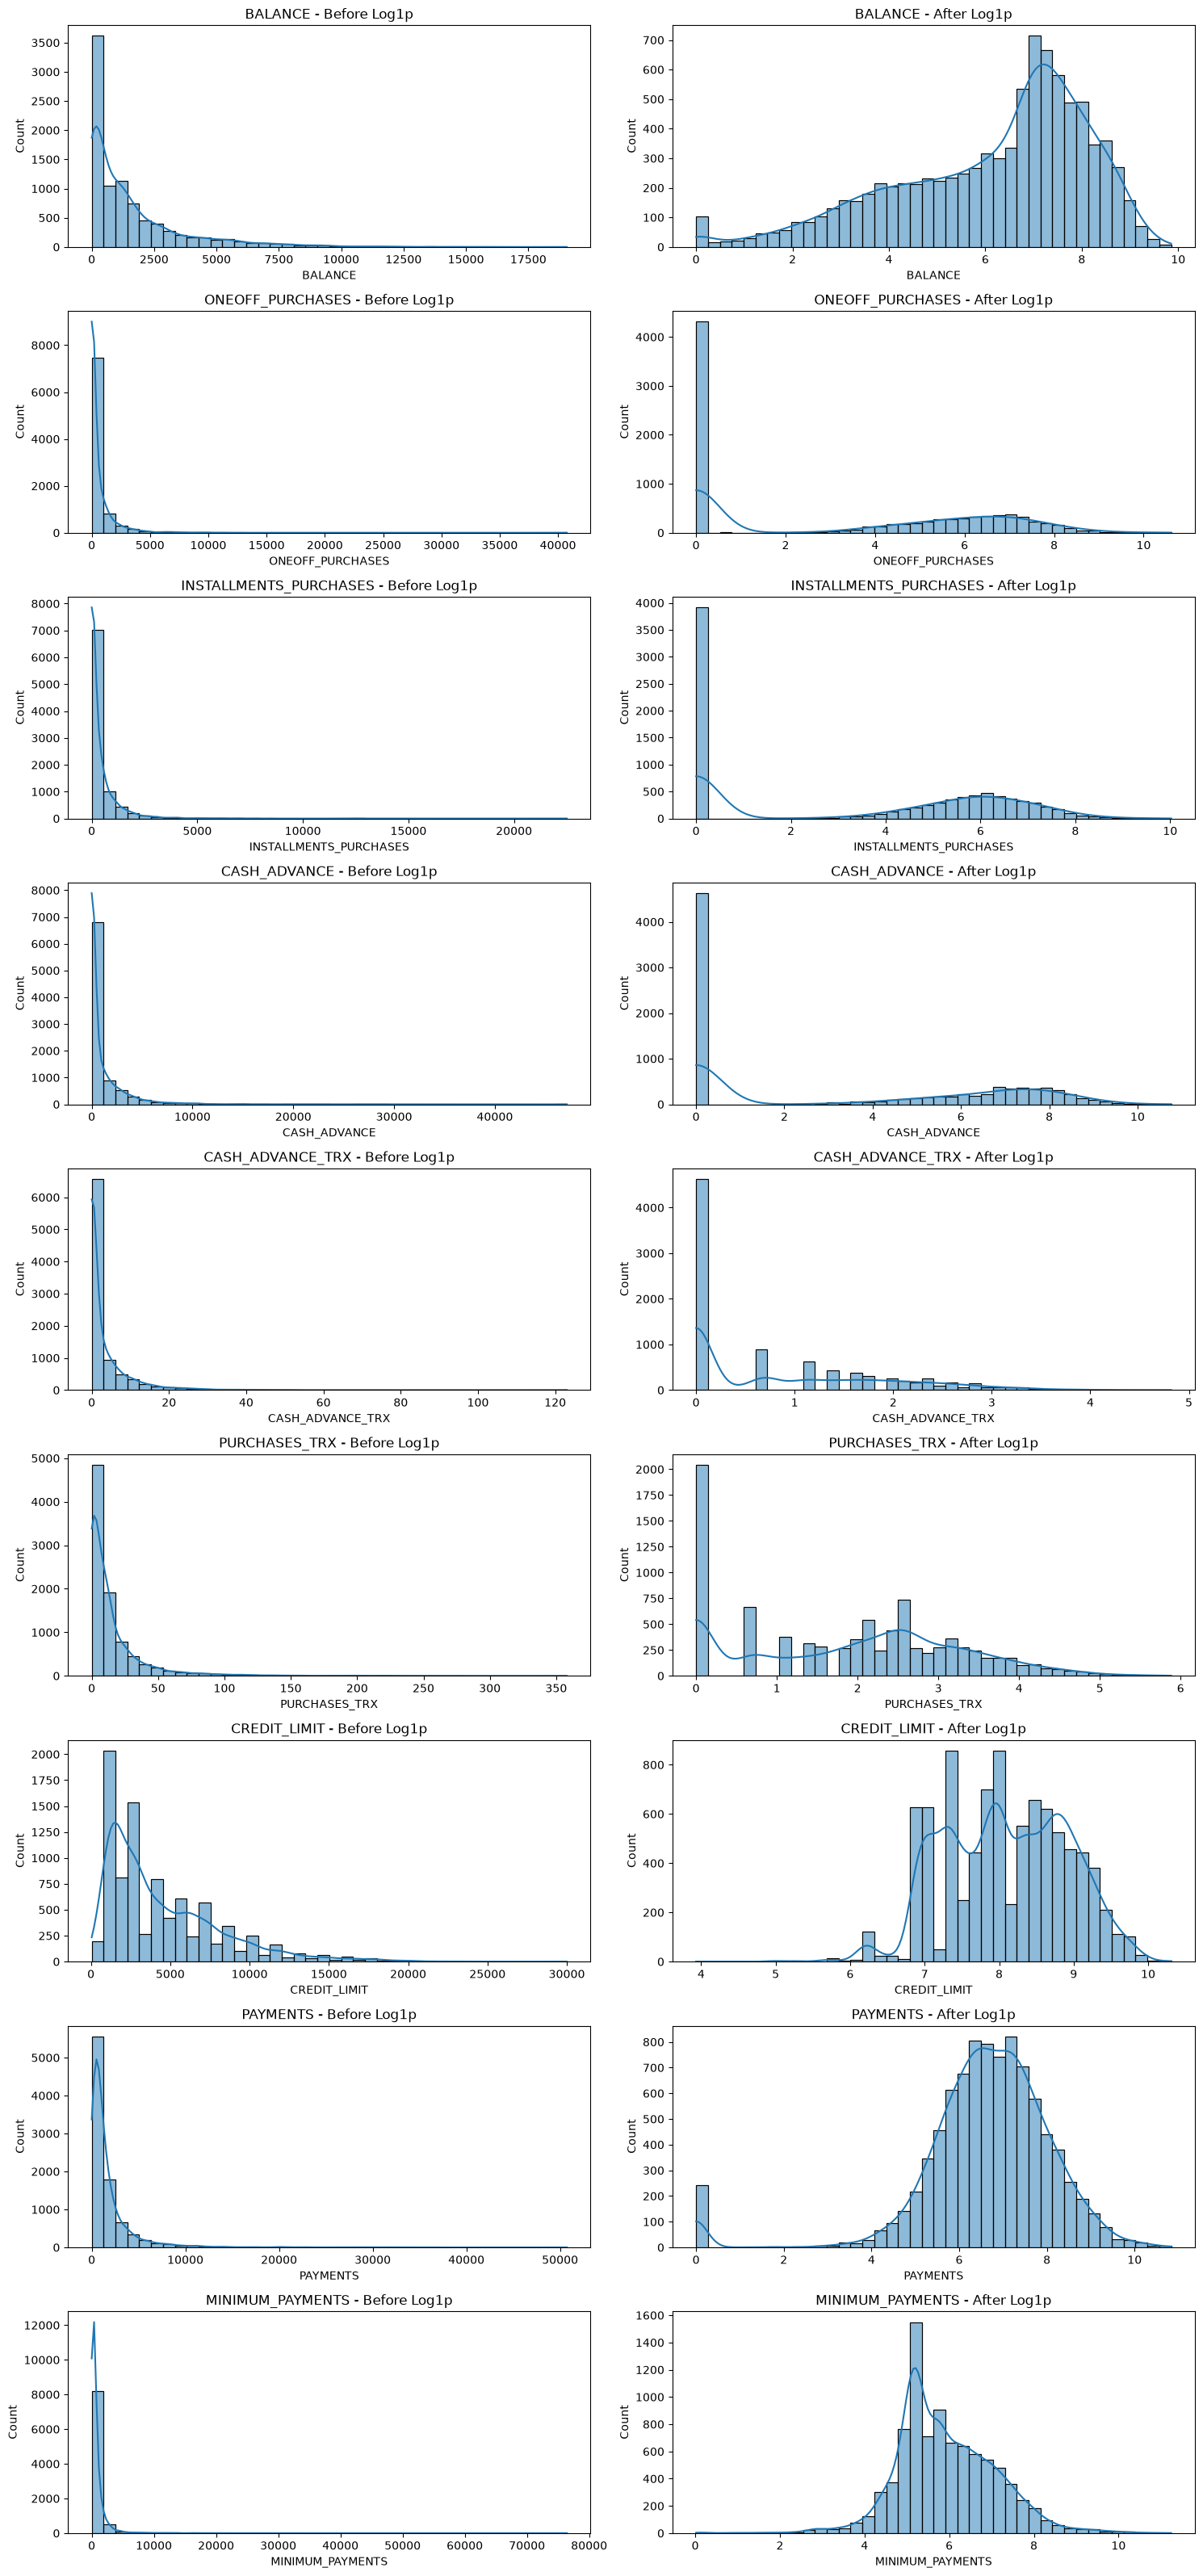

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Compare original and transformed distributions
fig, axes = plt.subplots(
    len(log_features), 2,
    figsize=(15, 32)
)

for i, feature in enumerate(log_features):

    # Before transformation
    sns.histplot(
        X_imputed[feature],
        bins=40,
        kde=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{feature} - Before Log1p")

    # After transformation
    sns.histplot(
        X_transformed[feature],
        bins=40,
        kde=True,
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"{feature} - After Log1p")

plt.tight_layout()
plt.show()

,Skewness
Original,5.9076
Square Root,1.9515
Log1p,-1.7783


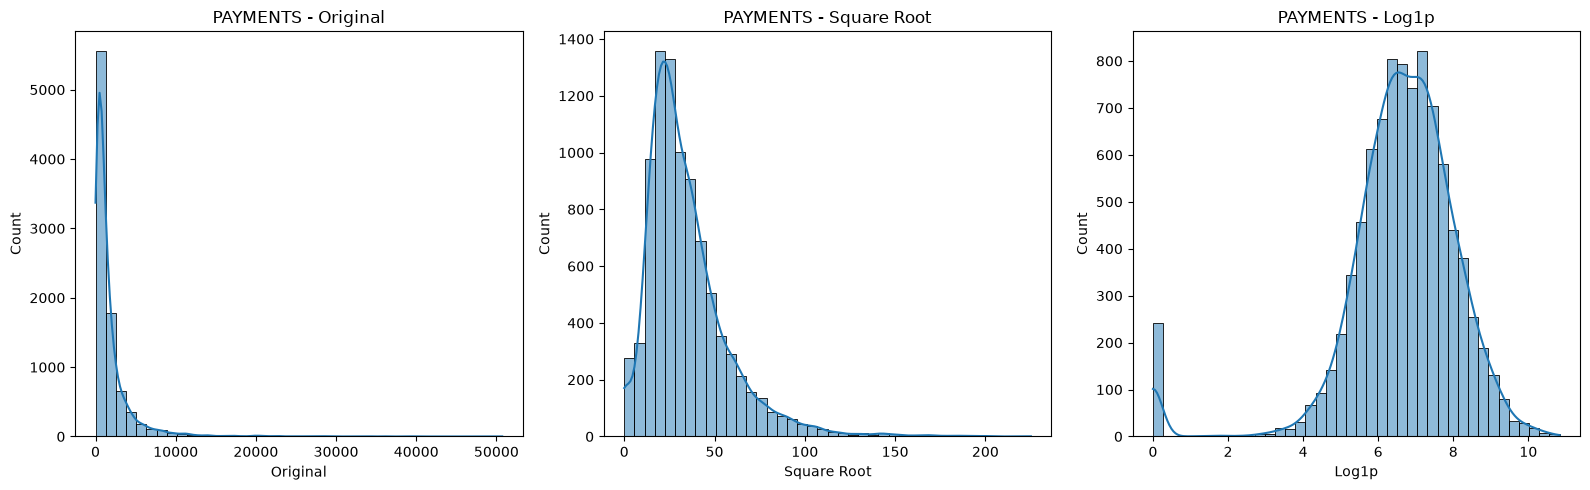

In [26]:
# Compare alternative transformations for PAYMENTS

payments_original = X_imputed["PAYMENTS"]

payments_comparison = pd.DataFrame({
    "Original": payments_original,
    "Square Root": np.sqrt(payments_original),
    "Log1p": np.log1p(payments_original)
})

# Compare skewness
payments_skewness = pd.DataFrame({
    "Skewness": payments_comparison.skew()
})

display(payments_skewness.round(4))

# Visual comparison
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for column, ax in zip(payments_comparison.columns, axes):
    sns.histplot(
        payments_comparison[column],
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"PAYMENTS - {column}")

plt.tight_layout()
plt.show()

## 5. Feature Standardisation

Apply StandardScaler to transform all selected features to a common scale.

Standardisation is important for K-Means because its distance calculations are sensitive to differences in feature magnitudes.

The transformed dataset will remain unchanged.

In [27]:
from sklearn.preprocessing import StandardScaler

# Initialise StandardScaler
scaler = StandardScaler()

# Fit and transform the dataset
X_scaled_array = scaler.fit_transform(X_transformed)

# Convert the scaled array back into a DataFrame
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X_transformed.columns,
    index=X_transformed.index
)

# Calculate scaling statistics
scaling_report = pd.DataFrame({
    "Mean": X_scaled.mean(),
    "Standard Deviation": X_scaled.std(ddof=0),
    "Minimum": X_scaled.min(),
    "Maximum": X_scaled.max()
})

print("SCALING VALIDATION")
display(scaling_report.round(4))

print("\nOriginal transformed shape:", X_transformed.shape)
print("Scaled dataset shape:", X_scaled.shape)

print("\nMissing values:", X_scaled.isnull().sum().sum())
print("Infinite values:", np.isinf(X_scaled.to_numpy()).sum())

# Validate the scaled dataset
assert X_scaled.shape == (8950, 16)
assert X_scaled.isnull().sum().sum() == 0
assert np.isfinite(X_scaled.to_numpy()).all()
assert np.allclose(X_scaled.mean().values, 0, atol=1e-10)
assert np.allclose(
    X_scaled.std(ddof=0).values, 1, atol=1e-10
)

assert X_scaled.columns.equals(X_transformed.columns)
assert X_scaled.index.equals(X_transformed.index)

print("\nStandardisation completed successfully!")

SCALING VALIDATION


,Mean,Standard Deviation,Minimum,Maximum
BALANCE,0.0,1.0,-3.0606,1.8343
BALANCE_FREQUENCY,0.0,1.0,-3.7033,0.5181
ONEOFF_PURCHASES,0.0,1.0,-0.9871,2.2831
INSTALLMENTS_PURCHASES,0.0,1.0,-1.0875,2.1633
CASH_ADVANCE,0.0,1.0,-0.9307,2.0868
PURCHASES_FREQUENCY,-0.0,1.0,-1.2218,1.2698
ONEOFF_PURCHASES_FREQUENCY,-0.0,1.0,-0.6787,2.6735
PURCHASES_INSTALLMENTS_FREQUENCY,0.0,1.0,-0.9170,1.5992
CASH_ADVANCE_FREQUENCY,0.0,1.0,-0.6753,6.8205
CASH_ADVANCE_TRX,-0.0,1.0,-0.8101,3.9660



Original transformed shape: (8950, 16)
Scaled dataset shape: (8950, 16)

Missing values: 0
Infinite values: 0

Standardisation completed successfully!


## 6. Final Preprocessing Validation

Validate the processed dataset for dimensions, missing values, infinite values, feature consistency, customer ID alignment, and zero-variance features.

In [28]:
# 1. Validate dataset dimensions
print("DATASET DIMENSIONS")
print("Original dataset:", df_raw.shape)
print("Selected features:", X_selected.shape)
print("Final scaled dataset:", X_scaled.shape)

# 2. Validate missing and infinite values
missing_count = X_scaled.isnull().sum().sum()
infinite_count = np.isinf(X_scaled.to_numpy()).sum()

print("\nDATA QUALITY")
print("Missing values:", missing_count)
print("Infinite values:", infinite_count)

# 3. Check numerical data types
print("\nDATA TYPES")
print("All numerical:", 
      X_scaled.select_dtypes(include=np.number).shape[1]
      == X_scaled.shape[1])

# 4. Check zero-variance features
zero_variance_features = X_scaled.columns[
    X_scaled.std(ddof=0) == 0
].tolist()

print("\nZero-variance features:", zero_variance_features)

# 5. Verify customer ID alignment
ids_aligned = (
    customer_ids.reset_index(drop=True).equals(
        df_raw["CUST_ID"].reset_index(drop=True)
    )
)

print("\nCustomer IDs aligned:", ids_aligned)
print("Unique customer IDs:", customer_ids.nunique())

# 6. Final assertions
assert X_scaled.shape == (8950, 16)
assert missing_count == 0
assert infinite_count == 0
assert len(zero_variance_features) == 0
assert ids_aligned
assert customer_ids.nunique() == len(customer_ids)
assert np.allclose(X_scaled.mean(), 0, atol=1e-10)
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-10)

print("\nALL PREPROCESSING VALIDATION CHECKS PASSED!")

DATASET DIMENSIONS
Original dataset: (8950, 18)
Selected features: (8950, 16)
Final scaled dataset: (8950, 16)

DATA QUALITY
Missing values: 0
Infinite values: 0

DATA TYPES
All numerical: True

Zero-variance features: []

Customer IDs aligned: True
Unique customer IDs: 8950

ALL PREPROCESSING VALIDATION CHECKS PASSED!


## 7. Save Processed Dataset and Preprocessing Artifacts

Save the final scaled customer features and fitted preprocessing objects for reuse during K-Means clustering.

Customer identifiers are retained separately and excluded from the clustering feature matrix.

In [29]:
import joblib
from pathlib import Path

# Identify project root directory
current_dir = Path.cwd()

possible_roots = [current_dir, current_dir.parent]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (path / "data").is_dir()
        and (path / "models").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate project root.")

# Create output directories
processed_dir = PROJECT_ROOT / "data" / "processed"
models_dir = PROJECT_ROOT / "models"

processed_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

# Attach customer IDs to scaled features
processed_data = pd.concat(
    [
        customer_ids.rename("CUST_ID"),
        X_scaled
    ],
    axis=1
)

# Define output paths
csv_path = (
    processed_dir / "credit_card_customer_features_scaled.csv"
)

artifact_path = models_dir / "preprocessing_artifacts.joblib"

# Save processed dataset
processed_data.to_csv(csv_path, index=False)

# Store fitted preprocessing objects and metadata
preprocessing_artifacts = {
    "imputer": imputer,
    "scaler": scaler,
    "selected_features": list(X_selected.columns),
    "log_features": log_features,
    "excluded_features": excluded_features,
    "imputation_strategy": "median",
    "transformation": "log1p",
    "scaling_method": "StandardScaler"
}

# Save artifacts
joblib.dump(preprocessing_artifacts, artifact_path)

# Verify saved CSV
saved_data = pd.read_csv(csv_path)

assert saved_data.shape == (8950, 17)
assert saved_data["CUST_ID"].equals(
    customer_ids.reset_index(drop=True)
)
assert saved_data.iloc[:, 1:].isnull().sum().sum() == 0

# Verify saved artifacts
loaded_artifacts = joblib.load(artifact_path)

assert "imputer" in loaded_artifacts
assert "scaler" in loaded_artifacts

print("PREPROCESSING FILES SAVED SUCCESSFULLY!")
print("\nProcessed CSV:", csv_path)
print("Artifact file:", artifact_path)

print("\nSaved dataset shape:", saved_data.shape)
print("Clustering features:", saved_data.shape[1] - 1)

print("\nArtifact components:")
print(list(loaded_artifacts.keys()))

PREPROCESSING FILES SAVED SUCCESSFULLY!

Processed CSV: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\data\processed\credit_card_customer_features_scaled.csv
Artifact file: c:\Users\ka100\OneDrive\Desktop\Credit-Card-Customer-Segmentation\models\preprocessing_artifacts.joblib

Saved dataset shape: (8950, 17)
Clustering features: 16

Artifact components:
['imputer', 'scaler', 'selected_features', 'log_features', 'excluded_features', 'imputation_strategy', 'transformation', 'scaling_method']
